In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import scipy 
from plotting_helper import *
%matplotlib inline

figures_path = 'figures/'
palette = plt.rcParams['axes.prop_cycle'].by_key()['color']  

In [2]:
def infinite_resources(parameters, state_var, dt ):
    
    x_vec = state_var[0]   #free mRNA concentrations
    xr_vec = state_var[1]  # bound mRNA ribosome concentrations
    y_vec = state_var[2]   #protein concentrations

    new_x_vec = x_vec + dt * (-parameters['α'] * x_vec  + parameters['β'] * xr_vec)
    new_xr_vec = xr_vec + dt * (parameters['α'] *  x_vec - parameters['β'] * xr_vec)
    new_y_vec = y_vec + dt * (parameters['β'] * xr_vec - parameters['γ'] * y_vec)

    return new_x_vec, new_xr_vec, new_y_vec


def finite_ribosomes(parameters, state_var, dt ):
    
    x_vec = state_var[0]   #free mRNA concentrations
    xr_vec = state_var[1]  # bound mRNA ribosome concentrations
    y_vec = state_var[2]   #protein concentrations
    r = parameters['R'] - np.sum(xr_vec)  #concentration of free ribosomes

    new_x_vec = x_vec + dt * (-parameters['α']  * r * x_vec  + parameters['β'] * xr_vec)
    new_xr_vec = xr_vec + dt * (parameters['α'] * r *  x_vec - parameters['β'] * xr_vec)
    new_y_vec = y_vec + dt * ( parameters['β'] * xr_vec - parameters['γ'] * y_vec)

    return new_x_vec, new_xr_vec, new_y_vec

def finite_protein(parameters, state_var, dt ):

    
    x_vec = state_var[0]   #free mRNA concentrations
    xr_vec = state_var[1]  # bound mRNA ribosome concentrations
    y_vec = state_var[2]   #protein concentrations
    r = parameters['R'] - np.sum(xr_vec)  #concentration of free ribosomes
    y_free = parameters['Y_max'] - np.sum(y_vec) 

    new_x_vec = x_vec + dt * (-parameters['α']  * r * x_vec  + parameters['β'] * xr_vec* y_free)
    new_xr_vec = xr_vec + dt * (parameters['α'] * r *  x_vec - parameters['β'] * xr_vec* y_free)
    new_y_vec = y_vec + dt * ( parameters['β'] * xr_vec* y_free - parameters['γ'] * y_vec)

    return new_x_vec, new_xr_vec, new_y_vec


def simulation_wrapper(state0, params, update, sim_time, dt): 
    
    states = np.zeros([int(sim_time/dt)+1, state0.shape[0], state0.shape[1]])
    states[0] = state0
    
    for t in range(int(sim_time/dt)): 
        states[t+1] = update(params, states[t], dt)
        
    return states[1:]

In [3]:
#set parameters: 
rng = np.random.RandomState(seed = 5)
γ = 0.05
α = 0.1
x_init = 1
dt = 0.001

Rs = np.linspace(0.01,10,20)
Ys = np.linspace(0.1, 5,10)

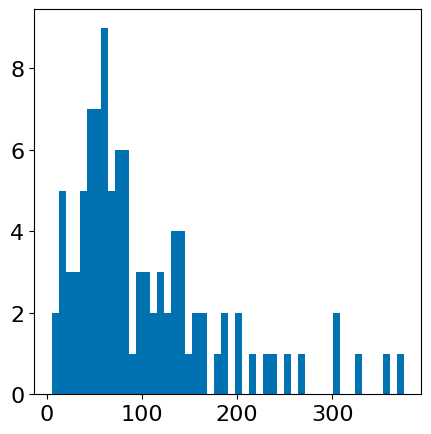

In [4]:
N = 100
Rs = np.linspace(0.01,110,num = 50)
mean, std = 2, 50
rng = np.random.RandomState(seed = 5)
l_samples = rng.gamma(mean, std, N)

fig, ax = plt.subplots(1,1, figsize = (5,5))
ax.hist(l_samples, bins = 50)
plt.show()

l_samples = np.sort(l_samples)

#prepare the different groups for later analyses
b1 = np.nonzero(l_samples < 50)[0][-1]
b2 = np.nonzero(l_samples < 100)[0][-1]
b3 = np.nonzero(l_samples < 150)[0][-1]
b4 = np.nonzero(l_samples < 200)[0][-1]

s_1k = np.arange(0,b1+1,1, dtype = int)
s_2k = np.arange(b1+1,b2+1,1, dtype = int)
s_3k = np.arange(b2+1,b3+1,1, dtype = int)
s_4k = np.arange(b3+1,b4+1,1, dtype = int)
b_4k = np.arange(b4+1,N,1, dtype = int)

In [ ]:
#####sample lengths and show that this is not just a two species competition, but that the competition is increaed
#####when multiple species exists. 
sim_time = 250 #this might be varied per simulation as we need to make sure all simulation reach their steady state
Y = N
results_lp = np.zeros([Rs.shape[0], int(sim_time/dt),3,N])

 
#prepare parameter dictionary
parameters = dict()
parameters['α'] = α
parameters['β'] = α/l_samples
parameters['γ'] = γ
parameters['l'] = l_samples
parameters['Y_max'] =  Y





x0 = np.ones([N])*x_init
init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 


for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]
    res = simulation_wrapper(init_state,parameters,finite_ribosomes, sim_time, dt) 
    results_lp[r]= res
    

    
layout = '''
    AABBC
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1]
width_ratios = [1,0.2,1,0.2,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()

ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']
ribo_state= ['WT', 'Fmr(-\y)']
ribo_ind = [0,-1]

for j in range(2): 
    for i in range(3): 
        ax = fig.add_subplot(gs[j*2,i*2])
        if i ==0: 
            ax.set_title(ribo_state[j])
        av1 = np.mean(results_lp[ribo_ind[j],:,2-i,s_1k], axis = 0)
        av2 = np.mean(results_lp[ribo_ind[j],:,2-i,s_2k], axis = 0)
        av3 = np.mean(results_lp[ribo_ind[j],:,2-i,s_3k], axis = 0)
        av4 = np.mean(results_lp[ribo_ind[j],:,2-i,s_4k], axis = 0)
        av5 = np.mean(results_lp[ribo_ind[j],:,2-i,b_4k], axis = 0)

        ax.plot(np.arange(0,sim_time,dt), av1, label = '<1k')
        ax.plot(np.arange(0,sim_time,dt), av2, label = '1-2k')
        ax.plot(np.arange(0,sim_time,dt), av3, label = '2-3k')
        ax.plot(np.arange(0,sim_time,dt), av4, label = '3-4k')
        ax.plot(np.arange(0,sim_time,dt), av5, label = '>4k')
        ax.set_xlabel('t')
        ax.set_ylabel(ylabels[i])
        if i == 2: 
            ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
        clear_axes(ax)

plt.show()



layout = '''
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()


#normalising the amounts for easier plotting
normed_y = np.diff(results_lp[:,-1,2,:].T, axis = 1) 
normed_xr = np.diff(results_lp[:,-1,1,:].T, axis = 1)
normed_x = np.diff(results_lp[:,-1,0,:].T , axis = 1)

maxy = 0.01 # np.amax(np.abs(normed_y))

    
ax = fig.add_subplot(gs[0,0])
hm = ax.imshow(normed_y, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
ax.set_title('Proteins')
fig.colorbar(hm, ax = ax )


ax = fig.add_subplot(gs[0,2])
hm = ax.imshow(normed_xr, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
ax.set_title('Translating mRNA')
fig.colorbar(hm, ax = ax )

ax = fig.add_subplot(gs[0,4])
hm = ax.imshow(normed_x, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
fig.colorbar(hm, ax = ax )
ax.set_title('Free mRNA')

plt.show()

layout = '''
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()
    
ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']

for i in range(3): 
    ax = fig.add_subplot(gs[0,i*2])
    av1 = np.mean(results_lp[:,-1, 2-i,s_1k], axis = 1)
    av2 = np.mean(results_lp[:,-1, 2-i,s_2k], axis = 1)
    av3 = np.mean(results_lp[:,-1, 2-i,s_3k], axis = 1)
    av4 = np.mean(results_lp[:,-1, 2-i,s_4k], axis = 1)
    av5 = np.mean(results_lp[:,-1, 2-i,b_4k], axis = 1)
    
    ax.plot(Rs, av1, label = '<1k')
    ax.plot(Rs, av2, label = '1-2k')
    ax.plot(Rs, av3, label = '2-3k')
    ax.plot(Rs, av4, label = '3-4k')
    ax.plot(Rs, av5, label = '>4k')
    ax.set_xlabel('R')
    ax.set_ylabel(ylabels[i])
    if i == 2: 
        ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
    clear_axes(ax)
    
plt.show()


#ratios of protein yield in stable state


layout = '''
    AABBC
    AABBC
    '''



fig = plt.figure(figsize=(8, 4))

height_ratios = [1,0.1]
width_ratios = [1,0.4,1,0.4,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=.8)
for a in list('ABC'):
    axes[a].set_axis_off()


ax = fig.add_subplot(gs[0,0])
ax.plot(Rs, results_lp[:,-1,2,-1]/results_lp[:,-1,2,0], label = 'low', color = palette[0])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
clear_axes(ax)
#ax.set_xlim(0,100)
ax.set_title('$\frac{longest}{shortest}$mRNAs')
#changed to be the same as the Osterweil lab paper

ax = fig.add_subplot(gs[0,2])
ax.plot(Rs, np.mean(results_lp[:,-1,2,b_4k], axis = 1)/np.mean(results_lp[:,-1,2,s_1k], axis = 1), label = 'low', color = palette[0])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
clear_axes(ax)
#ax.set_xlim(0,100)
ax.set_title('\frac{>4k}{<1k}mRNA')
#changed to be the same as the Osterweil lab paper

short_ind = np.concatenate((s_1k, s_2k), dtype = 'int')
long_ind = np.concatenate((s_3k, s_4k, b_4k), dtype = 'int')

ax = fig.add_subplot(gs[0,4])
ax.plot(Rs, np.mean(results_lp[:,-1,2,long_ind], axis = 1)/np.mean(results_lp[:,-1,2,short_ind], axis = 1), label = 'low', color = palette[0])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
clear_axes(ax)
#ax.set_xlim(0,100)
ax.set_title('\frac{>2k}{<2k}mRNA')
#changed to be the same as the Osterweil lab paper

plt.show()




In [ ]:


layout = '''
    AAAAA
    AAAAA
    BBBBB
    '''



fig = plt.figure(figsize=(8, 4))

height_ratios = [1,0.1, 1
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'AB':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='AB', postfix='', offset_left=.8)
for a in list('AB'):
    axes[a].set_axis_off()
                 
ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']

for i in range(3): 
    ax = fig.add_subplot(gs[0,i*2])
    av1 = np.mean(results_lp[:,-1, 2-i,s_1k], axis = 1)
    av2 = np.mean(results_lp[:,-1, 2-i,s_2k], axis = 1)
    av3 = np.mean(results_lp[:,-1, 2-i,s_3k], axis = 1)
    av4 = np.mean(results_lp[:,-1, 2-i,s_4k], axis = 1)
    av5 = np.mean(results_lp[:,-1, 2-i,b_4k], axis = 1)
    
    ax.plot(Rs, av1, label = '<1k')
    ax.plot(Rs, av2, label = '1-2k')
    ax.plot(Rs, av3, label = '2-3k')
    ax.plot(Rs, av4, label = '3-4k')
    ax.plot(Rs, av5, label = '>4k')
    ax.set_xlabel('R')
    ax.set_ylabel(ylabels[i])
    if i == 2: 
        ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
    clear_axes(ax)


ax = fig.add_subplot(gs[2,0])
ax.plot(Rs, results_lp[:,-1,2,-1]/results_lp[:,-1,2,0], label = 'low', color = palette[0])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
clear_axes(ax)
#ax.set_xlim(0,100)
ax.set_title('$\frac{longest}{shortest}$mRNAs')
#changed to be the same as the Osterweil lab paper

ax = fig.add_subplot(gs[2,2])
ax.plot(Rs, np.mean(results_lp[:,-1,2,b_4k], axis = 1)/np.mean(results_lp[:,-1,2,s_1k], axis = 1), label = 'low', color = palette[0])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
clear_axes(ax)
#ax.set_xlim(0,100)
ax.set_title('\frac{>4k}{<1k}mRNA')
#changed to be the same as the Osterweil lab paper

short_ind = np.concatenate((s_1k, s_2k), dtype = 'int')
long_ind = np.concatenate((s_3k, s_4k, b_4k), dtype = 'int')

ax = fig.add_subplot(gs[2,4])
ax.plot(Rs, np.mean(results_lp[:,-1,2,long_ind], axis = 1)/np.mean(results_lp[:,-1,2,short_ind], axis = 1), label = 'low', color = palette[0])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
clear_axes(ax)
#ax.set_xlim(0,100)
ax.set_title('\frac{>2k}{<2k}mRNA')
#changed to be the same as the Osterweil lab paper

plt.save_fig('ribosome_only_competition.pdf')               
plt.show()




This simulation shows, that we can achieve the desired relationship as proposed in Seo et al. with and without a competition for aminoacids. However, there is a subtle difference between the models when looking at the change in absolute protein yield. The ribosome only model does not show the surpression of long protein translation, but rather a difference in the amount it increases. 

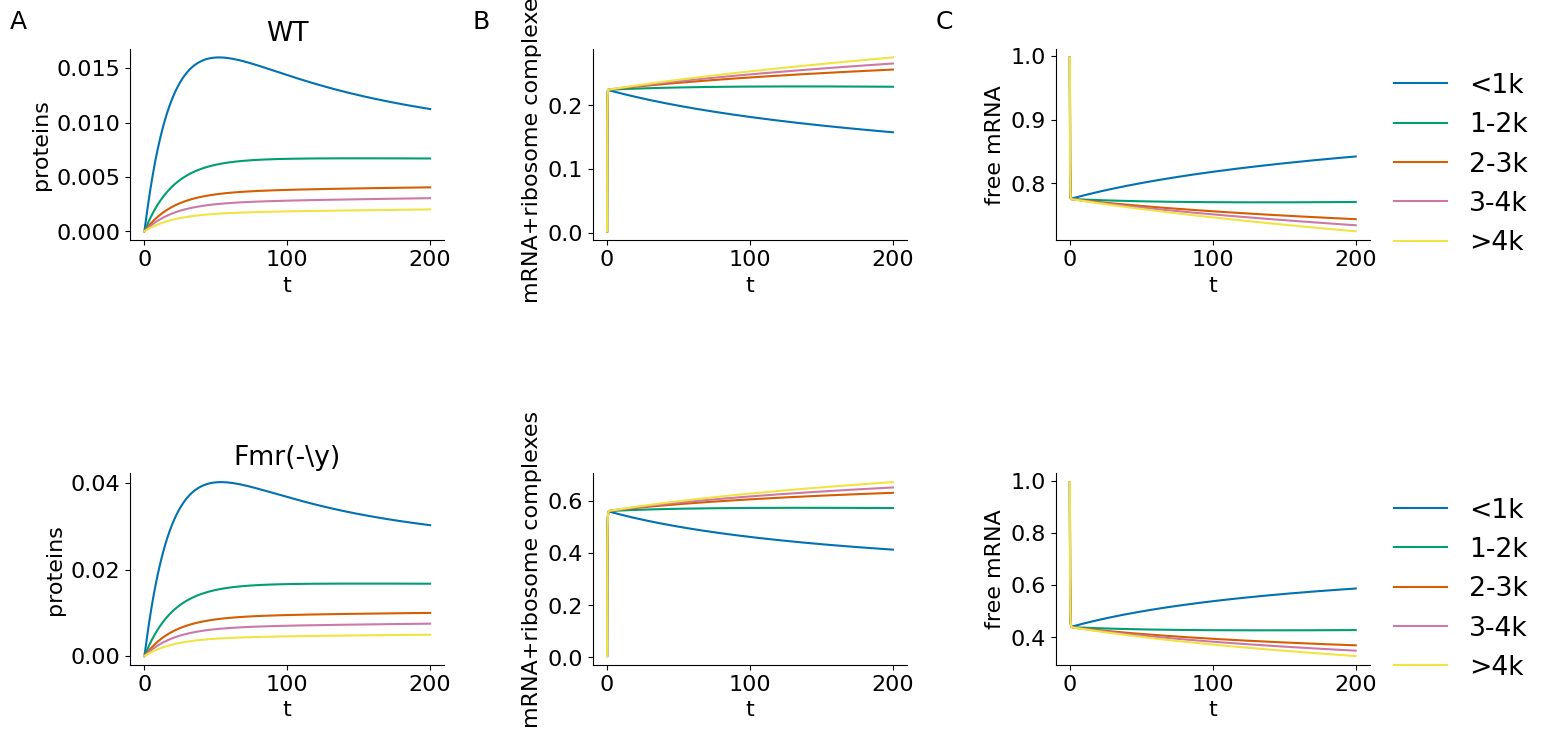

In [9]:
#plot two examples which are not the extremes of this simulation
#or i am doing a single simulation of two to show this. is faster and might be easier to analyse...
layout = '''
    AABBC
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1]
width_ratios = [1,0.2,1,0.2,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()

ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']
ribo_state= ['WT', 'Fmr(-\y)']
ribo_ind = [10,25]

for j in range(2): 
    for i in range(3): 
        ax = fig.add_subplot(gs[j*2,i*2])
        if i ==0: 
            ax.set_title(ribo_state[j])
        av1 = np.mean(results_lp[ribo_ind[j],:,2-i,s_1k], axis = 0)
        av2 = np.mean(results_lp[ribo_ind[j],:,2-i,s_2k], axis = 0)
        av3 = np.mean(results_lp[ribo_ind[j],:,2-i,s_3k], axis = 0)
        av4 = np.mean(results_lp[ribo_ind[j],:,2-i,s_4k], axis = 0)
        av5 = np.mean(results_lp[ribo_ind[j],:,2-i,b_4k], axis = 0)

        ax.plot(np.arange(0,sim_time,dt), av1, label = '<1k')
        ax.plot(np.arange(0,sim_time,dt), av2, label = '1-2k')
        ax.plot(np.arange(0,sim_time,dt), av3, label = '2-3k')
        ax.plot(np.arange(0,sim_time,dt), av4, label = '3-4k')
        ax.plot(np.arange(0,sim_time,dt), av5, label = '>4k')
        ax.set_xlabel('t')
        ax.set_ylabel(ylabels[i])
        if i == 2: 
            ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
        clear_axes(ax)

plt.show()





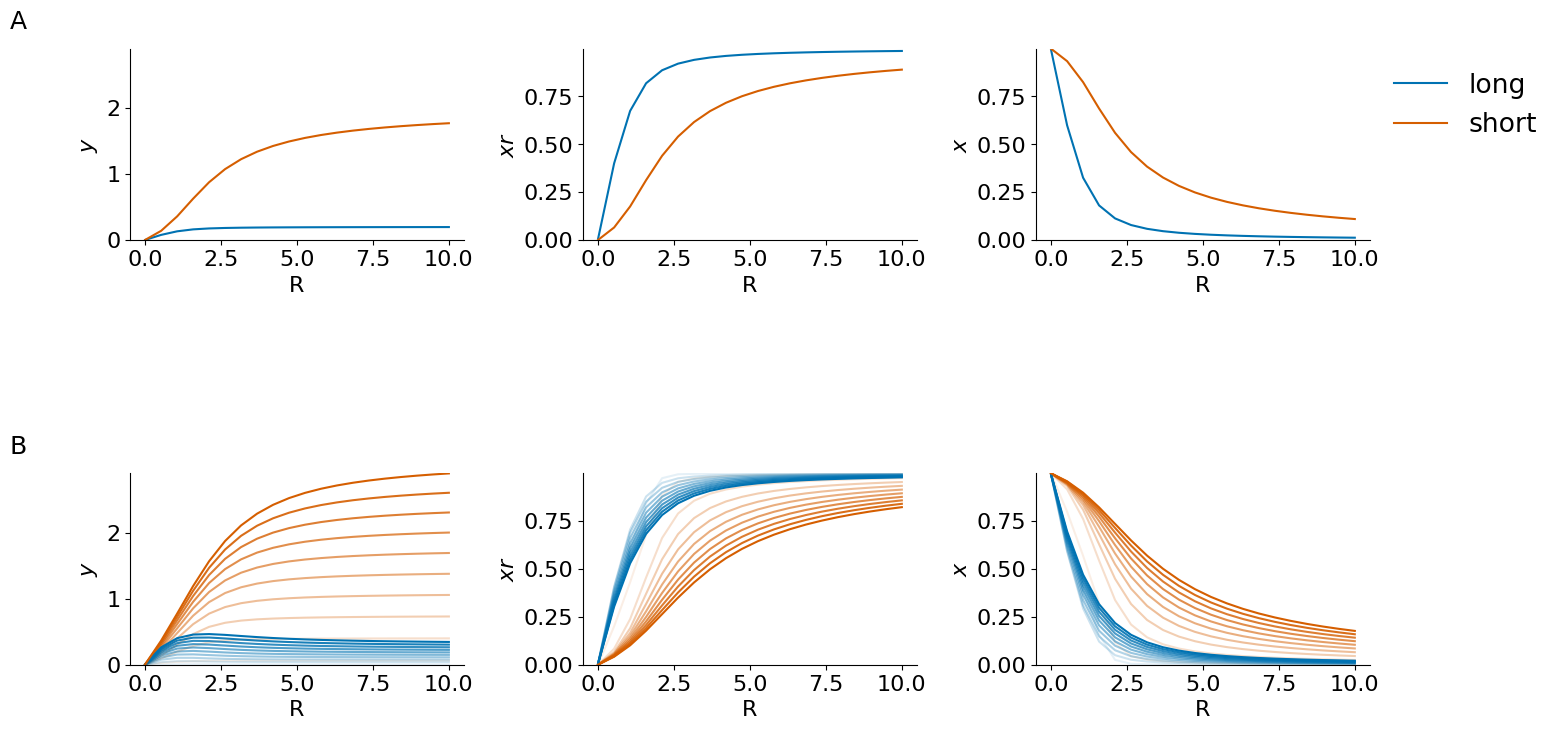

In [5]:
results_lr = np.zeros([Rs.shape[0], N,3])
results_lp = np.zeros([Rs.shape[0],Ys.shape[0], N,3])
 
#prepare parameter dictionary
parameters = dict()
parameters['α'] = α
parameters['β'] = α/l
parameters['γ'] = γ
parameters['l'] = l
parameters['Y_max'] = Y

for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]

    res = simulation_wrapper(init_state,parameters,finite_ribosomes, sim_time, dt) 
    results_lr[r]= res[-1].T
    
    for y in range(Ys.shape[0]):
        parameters['Y_max'] = Ys[y]
        res = simulation_wrapper(init_state,parameters,finite_protein, sim_time, dt) 
        results_lp[r,y]= res[-1].T

layout = '''
    AAAAA
    AAAAA
    BBBBB
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'AB':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='AB', postfix='', offset_left=1.2)
for a in list('AB'):
    axes[a].set_axis_off()


maxy = np.amax([np.amax(results_lp[:,:,:,2]),np.amax(results_lr[:,:,2])])
    
ax = fig.add_subplot(gs[0,0])
ax.plot(Rs, results_lr[:,1,2], label = 'long', color = palette[0])
ax.plot(Rs, results_lr[:,0,2], label = 'short', color = palette[2])
ax.set_xlabel('R')
ax.set_ylabel('$y$')
ax.set_ylim(0, maxy)
clear_axes(ax)

ax = fig.add_subplot(gs[2,0])
for y in range(Ys.shape[0]):
    ax.plot(Rs, results_lp[:,y,1,2], label = 'long', color = palette[0], alpha = asr[y])
    ax.plot(Rs, results_lp[:,y,0,2], label = 'short', color = palette[2], alpha = asr[y])
ax.set_xlabel('R')
ax.set_ylabel('$y$')
ax.set_ylim(0, maxy)
clear_axes(ax)

ax = fig.add_subplot(gs[0,2])
maxxr = np.amax([np.amax(results_lp[:,:,:,1]),np.amax(results_lr[:,:,1])])
ax.plot(Rs, results_lr[:,1,1], label = 'long', color = palette[0])
ax.plot(Rs, results_lr[:,0,1], label = 'short', color = palette[2])
ax.set_xlabel('R')
ax.set_ylabel('$xr$')
ax.set_ylim(0, maxxr)
clear_axes(ax)

ax = fig.add_subplot(gs[2,2])
for y in range(Ys.shape[0]):
    ax.plot(Rs, results_lp[:,y,1,1], label = 'long', color = palette[0], alpha = asr[y])
    ax.plot(Rs, results_lp[:,y,0,1], label = 'short', color = palette[2], alpha = asr[y])
ax.set_xlabel('R')
ax.set_ylabel('$xr$')
ax.set_ylim(0, maxxr)
clear_axes(ax)

ax = fig.add_subplot(gs[0,4])
maxx = np.amax([np.amax(results_lp[:,:,:,0]),np.amax(results_lr[:,:,0])])
ax.plot(Rs, results_lr[:,1,0], label = 'long', color = palette[0])
ax.plot(Rs, results_lr[:,0,0], label = 'short', color = palette[2])
ax.set_xlabel('R')
ax.set_ylabel('$x$')
ax.set_ylim(0, maxx)
ax.legend( bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)

ax = fig.add_subplot(gs[2,4])
for y in range(Ys.shape[0]):
    ax.plot(Rs, results_lp[:,y,1,0], label = 'long', color = palette[0], alpha = asr[y])
    ax.plot(Rs, results_lp[:,y,0,0], label = 'short', color = palette[2], alpha = asr[y])
ax.set_xlabel('R')
ax.set_ylabel('$x$')
ax.set_ylim(0, maxx)
clear_axes(ax)

plt.show()



This shows the competition in the total protein yeald. Interestingly, we dont see the similar competition in the actively translating complexes. However, this might be a limitation of the model as we push elongation and termination into the same step, rather than separate ones. 

A different model with an arbitrary termination step should be tested to see what is the buffering stage here. 

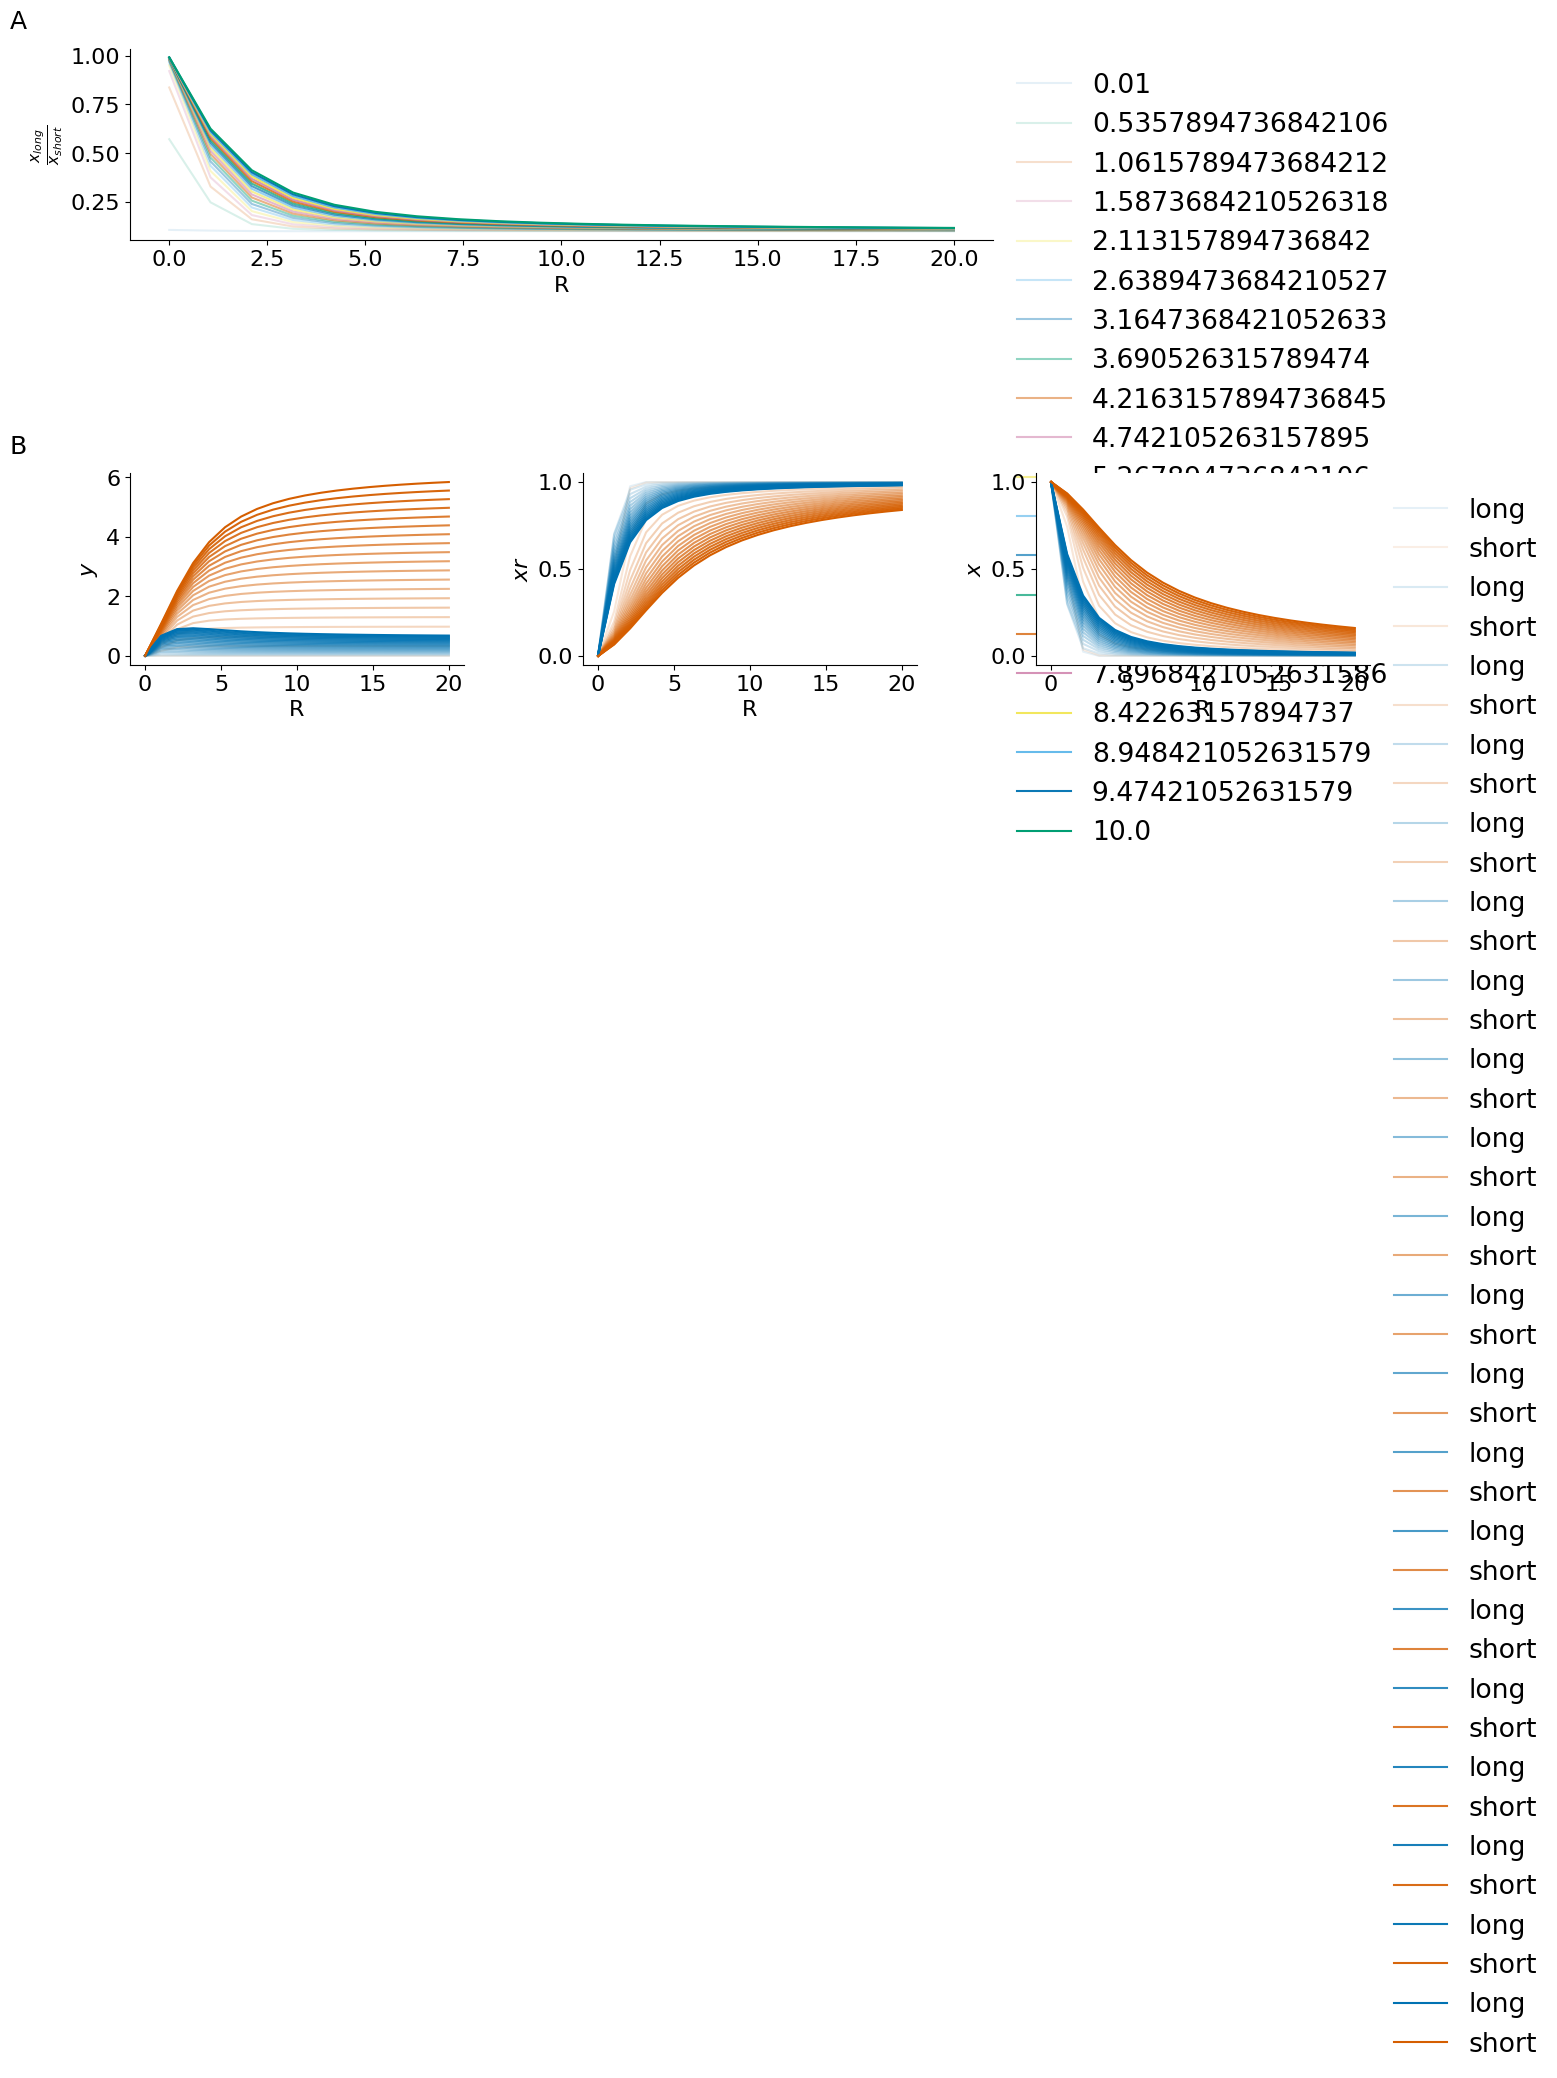

In [6]:
Rs = np.linspace(0.01,20,20)
Ys = np.linspace(0.01, 10,20)

results_lp = np.zeros([Rs.shape[0], Ys.shape[0], N,3])

parameters = dict()
parameters['α'] = α
parameters['β'] = α/l
parameters['γ'] = γ
parameters['l'] = l


for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]
    
    for y in range(Ys.shape[0]):
        parameters['Y_max'] = Ys[y]
        res = simulation_wrapper(init_state,parameters,finite_protein, sim_time, dt) 
        results_lp[r,y]= res[-1].T


layout = '''
    AAAAA
    AAAAA
    BBBBB
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'AB':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='AB', postfix='', offset_left=1.2)
for a in list('AB'):
    axes[a].set_axis_off()

ax = fig.add_subplot(gs[0,0:4])
asr = np.linspace(0.1,1,Ys.shape[0])
for y in range(Ys.shape[0]):
    ax.plot(Rs, results_lp[:,y,1,2]/results_lp[:,y,0,2], alpha = asr[y], label = Ys[y])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)



ax = fig.add_subplot(gs[2,0])
for y in range(Ys.shape[0]):
    ax.plot(Rs, results_lp[:,y,1,2], label = 'long', color = palette[0], alpha = asr[y])
    ax.plot(Rs, results_lp[:,y,0,2], label = 'short', color = palette[2], alpha = asr[y])
ax.set_xlabel('R')
ax.set_ylabel('$y$')
clear_axes(ax)

ax = fig.add_subplot(gs[2,2])
for y in range(Ys.shape[0]):
    ax.plot(Rs, results_lp[:,y,1,1], label = 'long', color = palette[0], alpha = asr[y])
    ax.plot(Rs, results_lp[:,y,0,1], label = 'short', color = palette[2], alpha = asr[y])
ax.set_xlabel('R')
ax.set_ylabel('$xr$')
clear_axes(ax)


ax = fig.add_subplot(gs[2,4])
for y in range(Ys.shape[0]):
    ax.plot(Rs, results_lp[:,y,1,0], label = 'long', color = palette[0], alpha = asr[y])
    ax.plot(Rs, results_lp[:,y,0,0], label = 'short', color = palette[2], alpha = asr[y])
ax.set_xlabel('R')
ax.set_ylabel('$x$')
ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)

plt.show()



Here we see that the protein resource has a start impact by increasing the competition for it. So we actually see the competition in the movement towards the saturated regime. 

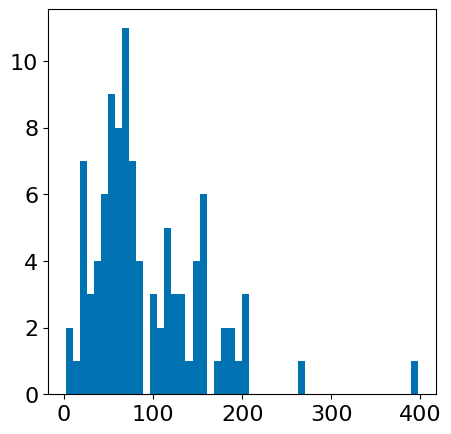

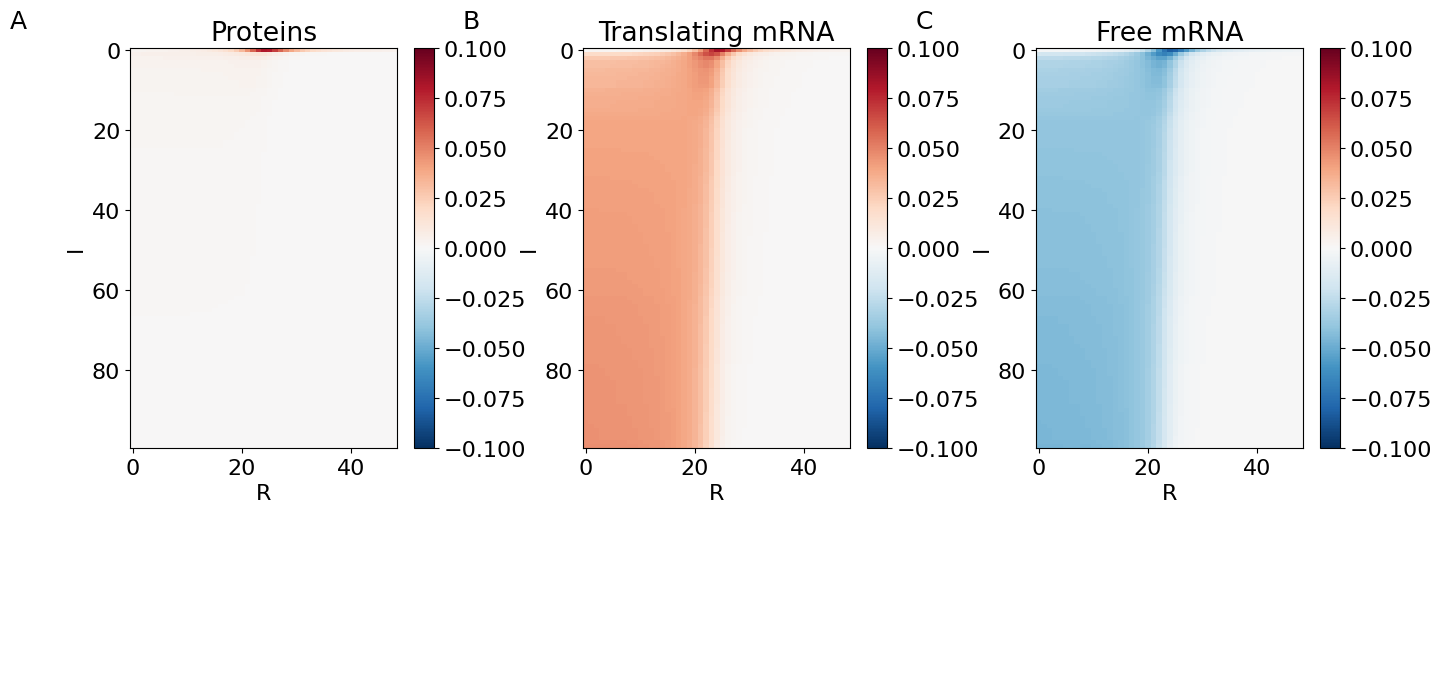

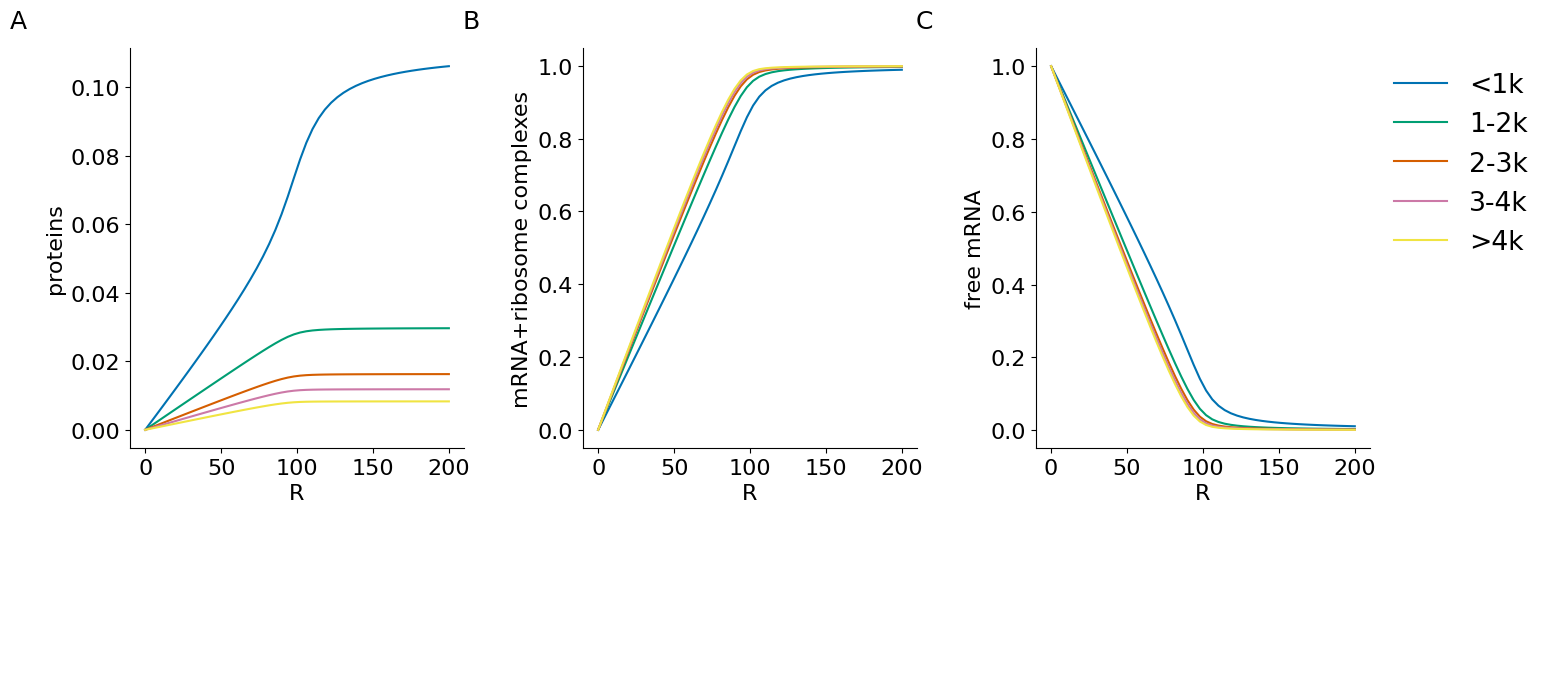

In [8]:
#####sample lengths and show that this is not just a two species competition, but that the competition is increaed
#####when multiple species exists. 
N = 100
Y = N
Rs = np.linspace(0.01,200,num = 50)

β = 0.1
α = 0.005

results_lp = np.zeros([Rs.shape[0], N,3])
mean, std = 2, 50
l_sampels = rng.gamma(mean, std, N)

fig, ax = plt.subplots(1,1, figsize = (5,5))
ax.hist(l_sampels, bins = 50)
plt.show()
 
#prepare parameter dictionary
parameters = dict()
parameters['α'] = α
parameters['β'] = β/np.sort(l_sampels)
parameters['γ'] = γ
parameters['l'] = np.sort(l_sampels)
parameters['Y_max'] =  Y

#prepare the different groups for later analyses
s_1k = np.nonzero([parameters['l'] < 50])[1]
s_2k = np.delete(np.nonzero([parameters['l'] < 100])[1], s_1k)
s_3k = np.delete(np.delete(np.nonzero([parameters['l'] < 150])[1], s_2k), s_1k)
s_4k = np.delete(np.delete(np.delete(np.nonzero([parameters['l'] < 200])[1], s_3k), s_2k), s_1k)
b_4k = np.nonzero([parameters['l'] >= 200])[1]

x0 = np.ones([N])*x_init
init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 


for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]
    res = simulation_wrapper(init_state,parameters,finite_ribosomes, sim_time, dt) 
    results_lp[r]= res[-1].T


layout = '''
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()


#normalising the amounts for easier plotting
normed_y = np.diff(results_lp[:,:,2].T, axis = 1) 
normed_xr = np.diff(results_lp[:,:,1].T, axis = 1)
normed_x = np.diff(results_lp[:,:,0].T , axis = 1)

maxy = 0.1 # np.amax(np.abs(normed_y))

    
ax = fig.add_subplot(gs[0,0])
hm = ax.imshow(normed_y, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
ax.set_title('Proteins')
fig.colorbar(hm, ax = ax )


ax = fig.add_subplot(gs[0,2])
hm = ax.imshow(normed_xr, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
ax.set_title('Translating mRNA')
fig.colorbar(hm, ax = ax )

ax = fig.add_subplot(gs[0,4])
hm = ax.imshow(normed_x, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
fig.colorbar(hm, ax = ax )
ax.set_title('Free mRNA')

plt.show()

layout = '''
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()
    
ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']

for i in range(3): 
    ax = fig.add_subplot(gs[0,i*2])
    av1 = np.mean(results_lp[:,s_1k,2-i], axis = 1)
    av2 = np.mean(results_lp[:,s_2k,2-i], axis = 1)
    av3 = np.mean(results_lp[:,s_3k,2-i], axis = 1)
    av4 = np.mean(results_lp[:,s_4k,2-i], axis = 1)
    av5 = np.mean(results_lp[:,b_4k,2-i], axis = 1)
    
    ax.plot(Rs, av1, label = '<1k')
    ax.plot(Rs, av2, label = '1-2k')
    ax.plot(Rs, av3, label = '2-3k')
    ax.plot(Rs, av4, label = '3-4k')
    ax.plot(Rs, av5, label = '>4k')
    ax.set_xlabel('R')
    ax.set_ylabel(ylabels[i])
    if i == 2: 
        ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
    clear_axes(ax)
    
plt.show()



Here we can see that all groups increase consistently and the shift is only a difference in the slope of the increases, not because one is supressing the other actively. 

This confirms our assumption that the competition is mitigated by 2 resources and not only an increase in ribosomes if there is no further feedback. 

An increase in ribosomes does increase the protein yield until it is reaches the ceiling value given by the rates under no contraines from the ribosomes